# Reliability Analysis

I have been unsure for the longest time in what analysis to use, if dff or spikes. Spikes has the advantage of better temporal resolution but the inconvenience of more sparsity compared to dFF. So a thorough comparison needs to be assessed. 

Questions that I want answer to:
- How does reliability compare between dFF and spikes?
    - In terms of the scatter plot of distance vs reliability
    - Cells accepted and rejected in both cases (how many cells are accepted in both cases and not?)
    - Receptive field of the cells in both cases
- How does distance modulation compare between dFF and spikes?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import *
import os
import pickle
colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'

imaging_filename = r'240731_SAM019_1'

imaging_dir = os.path.join(data_dir, imaging_filename)
result_dir = data_dir + '/' + str(imaging_filename) + '/results/0910'
object_filename = imaging_dir + '/' + imaging_filename + '_distance.pkl'
object_filename_spikes = imaging_dir + '/' + imaging_filename + '_distance_spikes.pkl'

if os.path.exists(object_filename):
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')
if os.path.exists(object_filename_spikes):
    with open(object_filename_spikes, 'rb') as f:
        S = pickle.load(f)
        print('Loaded DistanceAnalysis object with spikes')
        
S.extract_characteristics_all()
D.extract_characteristics_all()
# else:
#     D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF', run_session=True, n_iterations=100)

Loaded DistanceAnalysis object
Loaded DistanceAnalysis object with spikes
 Cell 616

(['un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'binocular',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'monocular',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'binocular',
  'binocular',
  'un-reliable',
  'un-modulated',
  'un-modulat

In [29]:
D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF', run_session=True, n_iterations=50)
S = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='spikes', run_session=True, n_iterations=50)

 Cell 616

# Changes in reliability

In [2]:
# compute cells accepted without median distance method
is_reliable_population_dff = []
reliability_population_dff = []
is_consistent_population_dff = []
distance_population_dff = []

# for cell in range(D.dFF.shape[0]):
#     
#     print(r'Cell ' + str(cell), end='\r')
#     
#     is_reliable, reliability, _, _ = D.compute_reliability(cell=cell, n_iterations=200, additional_reliability=False, block='two eye')
#     is_consistent, distance = D.is_active(cell, block='two eye')
#     is_reliable_population_dff.append(is_reliable)
#     reliability_population_dff.append(reliability)
#     is_consistent_population_dff.append(is_consistent)
#     distance_population_dff.append(distance)
    
# compute cells accepted without median distance method
is_reliable_population_spikes = []
reliability_population_spikes = []
is_consistent_population_spikes = []
distance_population_spikes = []

for cell in range(S.dFF.shape[0]):
    
    is_reliable, reliability, _, _ = S.compute_reliability(cell=cell, n_iterations=200, additional_reliability=False, block='two eye')
    is_consistent, distance = S.is_active(cell, block='two eye')
    is_reliable_population_spikes.append(is_reliable)
    reliability_population_spikes.append(reliability)
    is_consistent_population_spikes.append(is_consistent)
    distance_population_spikes.append(distance)


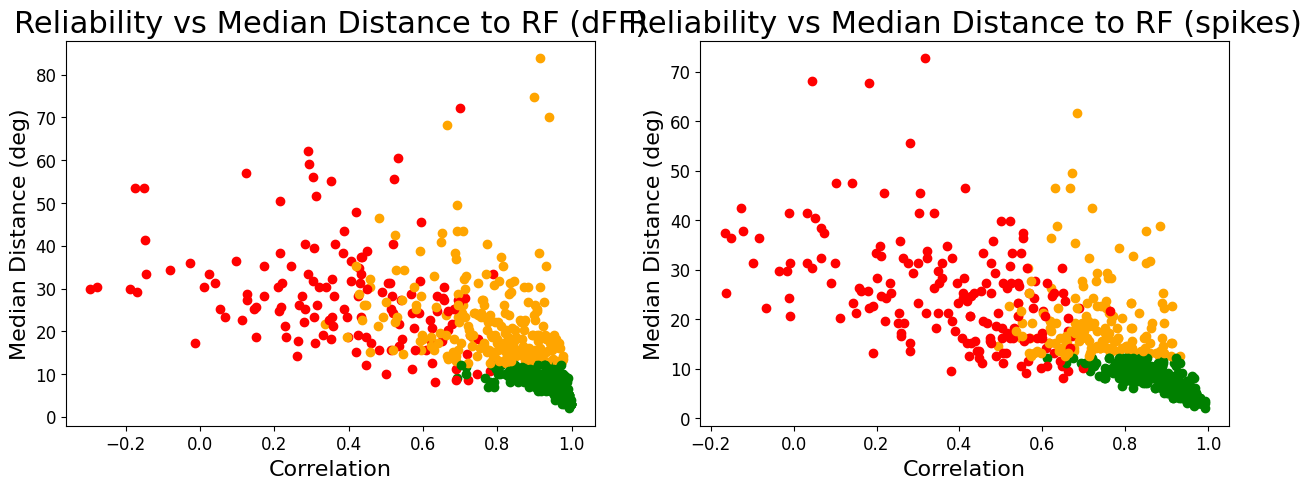

In [14]:
plt.subplots(1, 2, figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in range(len(is_reliable_population_dff)):
    if is_reliable_population_dff[i] and is_consistent_population_dff[i]:
        plt.scatter(reliability_population_dff[i], distance_population_dff[i], color='green')
    elif is_reliable_population_dff[i] and not is_consistent_population_dff[i]:
        plt.scatter(reliability_population_dff[i], distance_population_dff[i], color='orange')
    else:
        plt.scatter(reliability_population_dff[i], distance_population_dff[i], color='red')
    
plt.xlabel('Correlation', fontsize=16)
plt.ylabel('Median Distance (deg)', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.title('Reliability vs Median Distance to RF (dFF)', fontsize=22)
plt.legend(['Reliable and Consistent', 'Reliable and Not Consistent', 'Not Reliable'], loc='upper left', fontsize=12)

plt.subplot(1, 2, 2)
for i in range(len(is_reliable_population_spikes)):
    if is_reliable_population_spikes[i] and is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='green')
    elif is_reliable_population_spikes[i] and not is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='orange')
    else:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='red')

# set default params
# Reset to default settings
plt.rcdefaults()

plt.xlabel('Correlation', fontsize=16)
plt.ylabel('Median Distance (deg)', fontsize=16)
plt.title('Reliability vs Median Distance to RF (spikes)', fontsize=22)
# make xticks and labels bigger
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# add legend
plt.legend(['Reliable and Consistent', 'Reliable and Not Consistent', 'Not Reliable'], loc='upper left', fontsize=12)
plt.show()



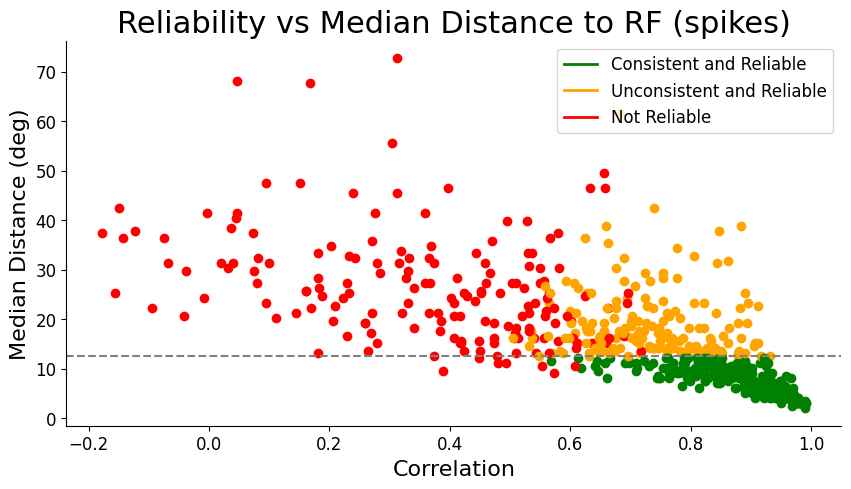

In [4]:
plt.figure(figsize=(10, 5))
for i in range(len(is_reliable_population_spikes)):
    if is_reliable_population_spikes[i] and is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='green')
    elif is_reliable_population_spikes[i] and not is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='orange')
    else:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='red')

# set default params
# Reset to default settings
# add horizontal line
plt.axhline(12.5, color='gray', linestyle='--', label='Median Distance')

plt.xlabel('Between Trial CC', fontsize=16)
plt.ylabel('Median Distance (deg)', fontsize=16)
plt.title('Reliability of cells', fontsize=22)
# make xticks and labels bigger
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
# add legend
# create legend
legend_elements = [Line2D([0], [0], color='green', lw=2, label='Visually driven and RF-stable  '),
                       Line2D([0], [0], color='orange', lw=2, label='Visually driven and RF-unstable'),
                       Line2D([0], [0], color='red', lw=2, label='Not visually driven')]
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)

# remove splines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

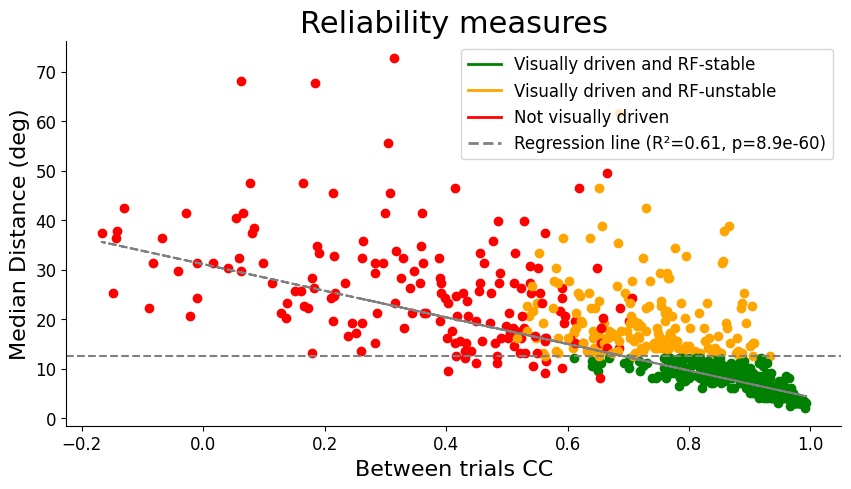

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Filter data for regression
x = np.array(reliability_population_spikes)
y = np.array(distance_population_spikes)
mask = np.array(is_reliable_population_spikes) & np.array(is_consistent_population_spikes)
x_filtered = x[mask]
y_filtered = y[mask]

# Compute regression line
slope, intercept, r_value, p_value, std_err = linregress(x_filtered, y_filtered)
regression_line = slope * x + intercept

plt.figure(figsize=(10, 5))
for i in range(len(is_reliable_population_spikes)):
    if is_reliable_population_spikes[i] and is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='green')
    elif is_reliable_population_spikes[i] and not is_consistent_population_spikes[i]:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='orange')
    else:
        plt.scatter(reliability_population_spikes[i], distance_population_spikes[i], color='red')

# Plot regression line
plt.plot(x, regression_line, color='gray', linestyle='--', label=f'Regression line (R²={r_value**2:.2f}, p={p_value:.2g})')

# Add horizontal line
plt.axhline(12.5, color='gray', linestyle='--', label='Median Distance')

plt.xlabel('Between trials CC', fontsize=16)
plt.ylabel('Median Distance (deg)', fontsize=16)
plt.title('Reliability measures', fontsize=22)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Create legend
legend_elements = [
    Line2D([0], [0], color='green', lw=2, label='Visually driven and RF-stable'),
    Line2D([0], [0], color='orange', lw=2, label='Visually driven and RF-unstable'),
    Line2D([0], [0], color='red', lw=2, label='Not visually driven'),
    Line2D([0], [0], color='gray', lw=2, linestyle='--', label=f'Regression line (R²={r_value**2:.2f}, p={p_value:.2g})')
]
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)

# Remove splines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

In [99]:
for i in range(len(is_reliable_population_dff)):
    if is_reliable_population_dff[i] and not is_consistent_population_dff[i]:
        plot_cell_reliability(D, cell=i, block='two eye', n_iterations=100)
        plt.savefig(result_dir + '/reliability_rejections_dff/' + str(i) + '_dFF.png')
        plt.close()
        
for i in range(len(is_reliable_population_spikes)):
    if is_reliable_population_spikes[i] and not is_consistent_population_spikes[i]:
        plot_cell_reliability(S, cell=i, block='two eye', n_iterations=100)
        plt.savefig(result_dir + '/reliability_rejections_spikes/' + str(i) + '_spikes.png')
        plt.close()

In [ ]:
D.extract_characteristics_all()
S.extract_characteristics_all()

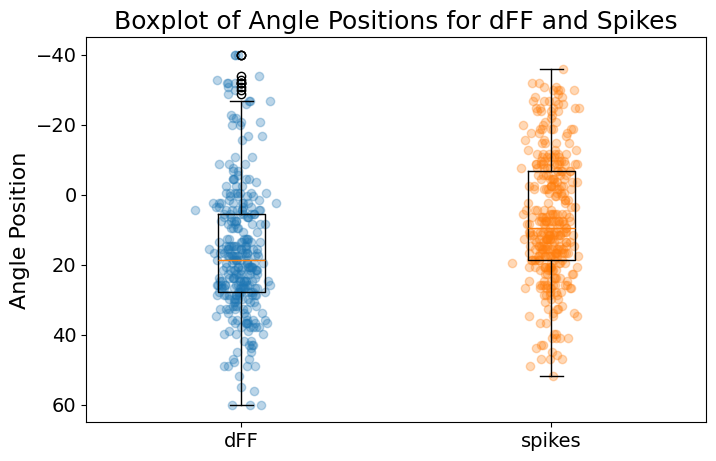

In [126]:
# find where D.stats['type'] is not un-reliable
reliable = np.where(np.array(D.stats['type']) != 'un-reliable')[0]
angle_dff = np.array(D.stats['preferred_angle'])[reliable]

reliable = np.where(np.array(S.stats['type']) != 'un-reliable')[0]
angle_spikes = np.array(S.stats['preferred_angle'])[reliable]

data = [angle_dff, angle_spikes]

# Create boxplot
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(data, labels=['dFF', 'spikes'] )


# Add scatter points
for i, category in enumerate(data):
    y = category
    x = np.random.normal(i + 1, 0.04, size=len(y))  # Add some random noise to the x-axis for better visualization
    ax.scatter(x, y, alpha=0.3)

# Add labels and title
ax.set_ylabel('Angle Position')
ax.set_title('Boxplot of Angle Positions for dFF and Spikes')

# Show plot
plt.show()

[300, 265, 27, 22, 3]
[262, 302, 35, 16, 2]


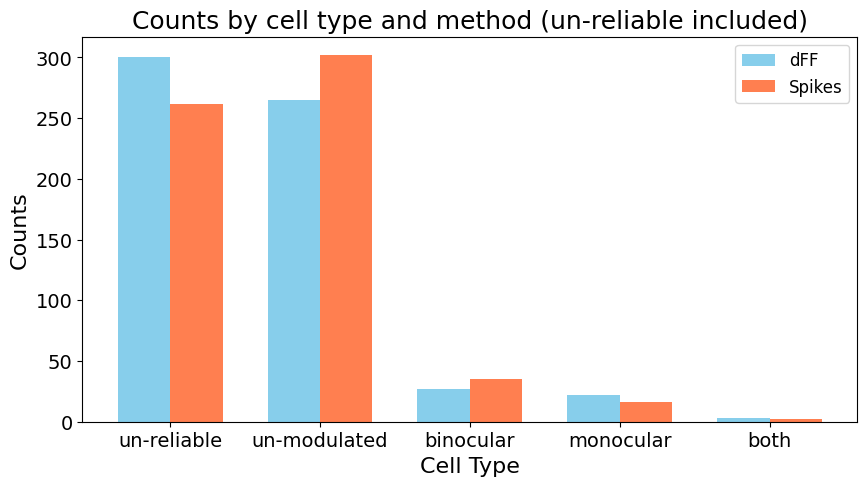

In [152]:
# do bar plot with cell type for both dFF and spikes
categories = ['un-reliable', 'un-modulated', 'binocular', 'monocular', 'both']
counts_dff = [D.stats['type'].count(cat) for cat in categories]
counts_spikes = [S.stats['type'].count(cat) for cat in categories]

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, counts_dff, width, label='dFF', color='skyblue')
rects2 = ax.bar(x + width/2, counts_spikes, width, label='Spikes', color='coral')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Counts')
ax.set_title('Counts by cell type and method (un-reliable included)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

print(counts_dff)
print(counts_spikes)

In [181]:
# for all the cells that are classified as binocular, monocular and both, find the ones in which spikes and dff do not agree
# D.compute_distance_modulation_all_cells(block='two eye')
# S.compute_distance_modulation_all_cells(block='two eye')
# 
# D.compute_distance_modulation_all_cells(block='one eye')
# S.compute_distance_modulation_all_cells(block='one eye')

D.extract_characteristics_all()
S.extract_characteristics_all()

binocular_dff = set(np.where(np.array(D.stats['type']) == 'binocular')[0])
binocular_spikes = set(np.where(np.array(S.stats['type']) == 'binocular')[0])

monocular_dff = set(np.where(np.array(D.stats['type']) == 'monocular')[0])
monocular_spikes = set(np.where(np.array(S.stats['type']) == 'monocular')[0])

both_dff = set(np.where(np.array(D.stats['type']) == 'both')[0])
both_spikes = set(np.where(np.array(S.stats['type']) == 'both')[0])

binocular_disagree = binocular_dff.symmetric_difference(binocular_spikes)
monocular_disagree = monocular_dff.symmetric_difference(monocular_spikes)
both_disagree = both_dff.symmetric_difference(both_spikes)

for cells in [binocular_disagree, monocular_disagree, both_disagree]:
    
    for cell in cells:
        plot_trials_ordered_2(D, cell=cell, title=D.stats['type'][cell])
        plt.savefig(result_dir + '/disagreements/' + str(cell) + '_dff.png')
        plt.close()
        
        plot_trials_ordered_2(S, cell=cell, title=S.stats['type'][cell])
        plt.savefig(result_dir + '/disagreements/' + str(cell) + '_spikes.png')
        plt.close() 

 Cell 616

In [184]:
for cell in range(D.dFF.shape[0]):
    
    if S.stats['type'][cell] == 'binocular':
        saving_dir = result_dir + '/binocular_spikes/' + str(cell) + '_spikes.png'
    elif S.stats['type'][cell] == 'monocular':
        saving_dir = result_dir + '/monocular_spikes/' + str(cell) + '_spikes.png'
    elif S.stats['type'][cell] == 'both':
        saving_dir = result_dir + '/both_spikes/' + str(cell) + '_spikes.png'
    elif S.stats['type'][cell] == 'un-modulated':
        saving_dir = result_dir + '/none_spikes/' + str(cell) + '_spikes.png'
    else:
        saving_dir = result_dir + '/unreliable_spikes/' + str(cell) + '_spikes.png'
        
    plot_trials_ordered_2(S, cell=cell, title= ' ' + S.stats['type'][cell])
    plt.savefig(saving_dir)
    plt.close()

In [157]:
# Example vectors
vector1 = [1, 2, 3, 4, 5]
vector2 = [4, 5, 6, 7, 8]

# Convert vectors to sets
set1 = set(vector1)
set2 = set(vector2)

# Find elements that are in only one of the two sets
unique_elements = set1.symmetric_difference(set2)

# Convert the result back to a list if needed
unique_elements_list = list(unique_elements)

print("Elements in only one of the two vectors:", unique_elements_list)

Elements in only one of the two vectors: [1, 2, 3, 6, 7, 8]


In [156]:
# get cells that are classified as binocular with spikes but not with dff
binocular_disagree = np.setdiff1d(binocular_spikes, binocular_dff, assume_unique=True)
print(binocular_disagree)

# now the opposite
binocular_disagree = np.setdiff1d(binocular_dff, binocular_spikes)
print(binocular_disagree)

[ 49  69  78 113 152 217 219 349 372 377 414 426 491 579 592]
[198 319 359 376 389 481 514]


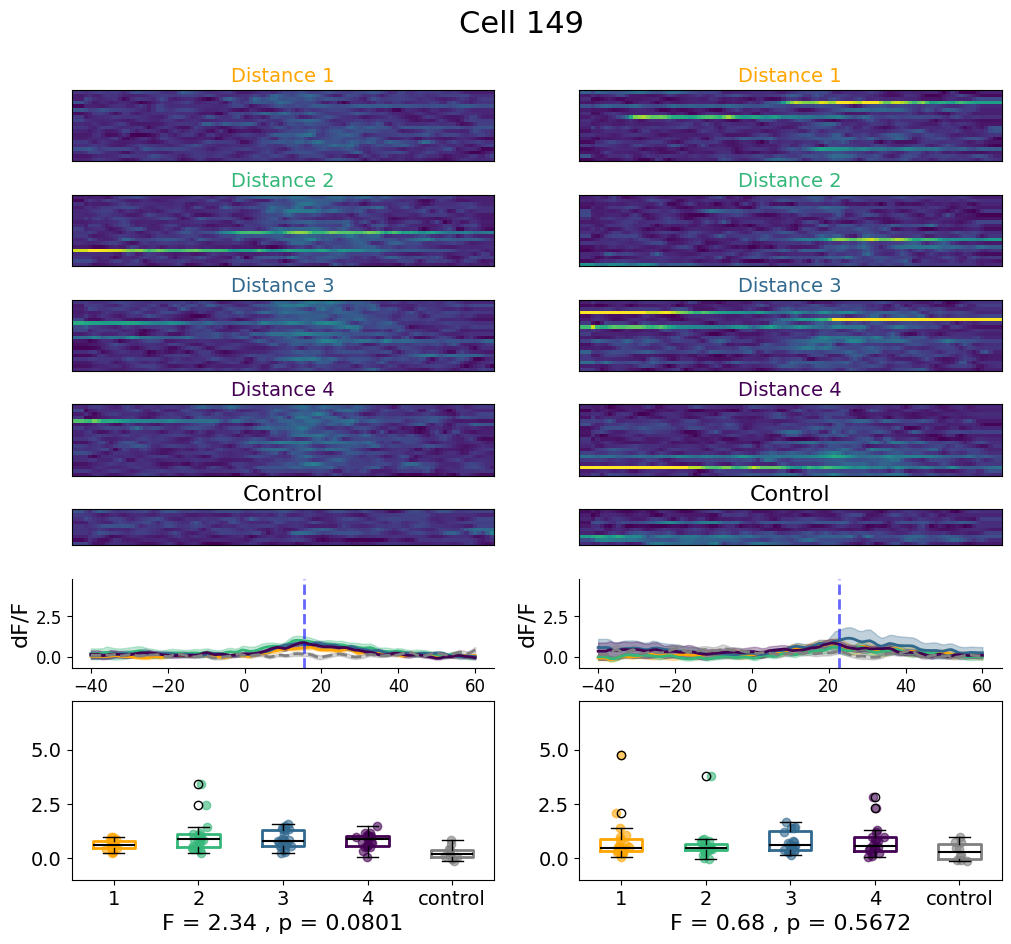

In [138]:
plot_trials_ordered_2(D, cell=149)

In [179]:
# D.compute_distance_modulation_all_cells(block='two eye')
# S.compute_distance_modulation_all_cells(block='two eye')
# D.compute_distance_modulation_all_cells(block='one eye')
# S.compute_distance_modulation_all_cells(block='one eye')

print(D.compute_distance_modulation(cell=377, block='two eye')[0])
print(D.stats['is_modulated_two_eye'][377])
print(D.extract_modulation_cell(cell=377))


True
True
binocular


# Example of a cell that I don't like using this method

KstestResult(statistic=1.0, pvalue=0.0, statistic_location=0.8496251660676746, statistic_sign=1)
3.3797731655950987


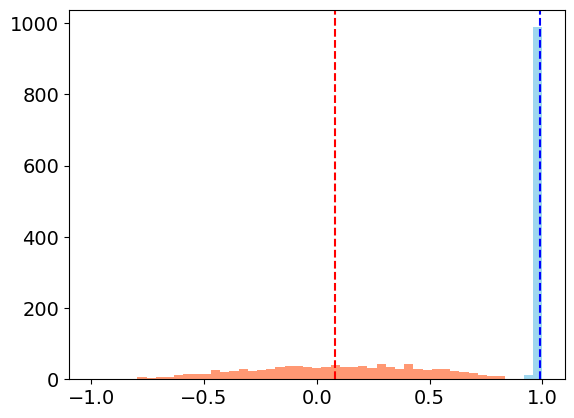

In [65]:
from scipy import stats

D.activity_mode = 'spikes'
is_reliable, reliability, corr_shifted, corr_real = D.compute_reliability(cell=350, n_iterations=1000, block='two eye')

stats = stats.kstest(corr_shifted, corr_real)
print(stats)

plt.figure()
bins = np.linspace(-1, 1, 50)

# plot corr_real and shifted in the same histogram
plt.hist(corr_shifted, bins, alpha=0.8, label='Shuffled', color='coral')
plt.hist(corr_real, bins, alpha=0.8, label='Real', color='skyblue')

# plot the mean lines for shuffled and real
plt.axvline(np.mean(corr_shifted), color='red', linestyle='--', label='Mean Shuffled')
plt.axvline(np.mean(corr_real), color='blue', linestyle='--', label='Mean Real')

# compute cohen d for these two distributions
mean_diff = np.mean(corr_real) - np.mean(corr_shifted)
std_diff = np.sqrt((np.std(corr_real) ** 2 + np.std(corr_shifted) ** 2) / 2)
cohen_d = mean_diff / std_diff
print(cohen_d)

Reliability non-normalized 0.9983268590602367
Is reliable True


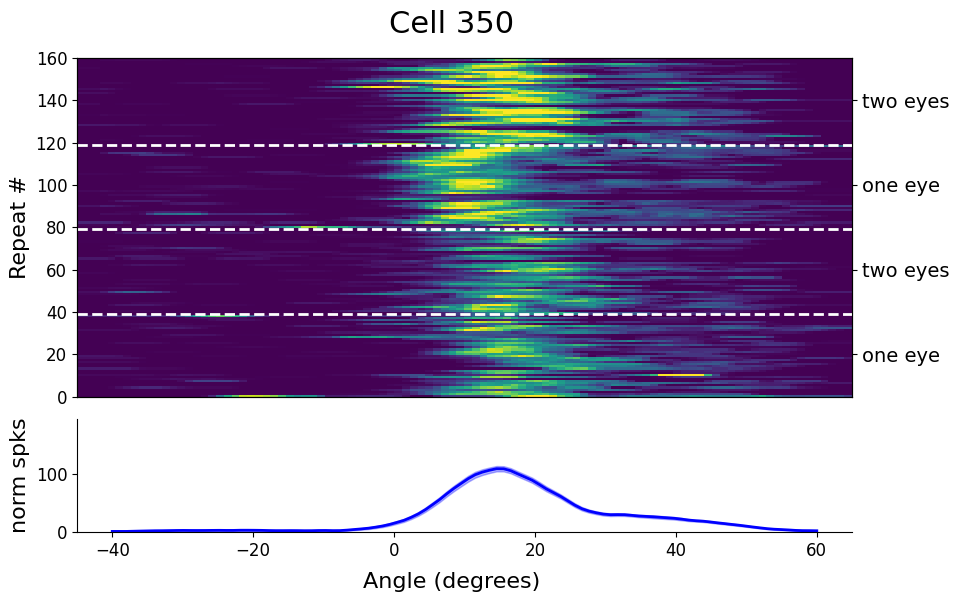

In [186]:
cell = 350
is_reliable, reliability, corr_shifted, corr_real = D.compute_reliability(cell=cell, n_iterations=200)
print('Reliability non-normalized', reliability)
print('Is reliable', is_reliable)

plot_trials(S, cell=cell)

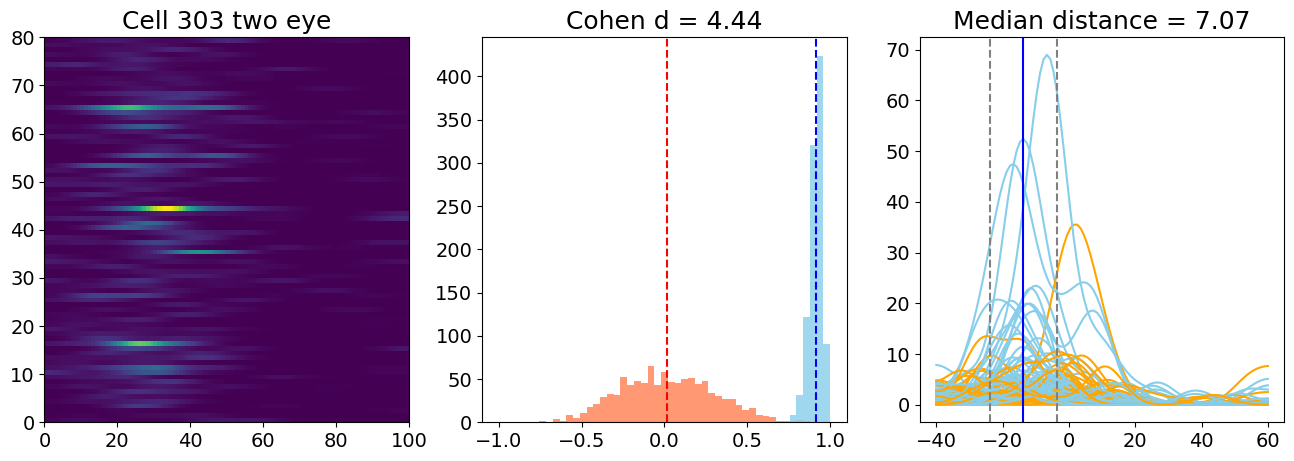

In [82]:
D.activity_mode = 'spikes'
plot_cell_reliability(D, cell=303, block='two eye', n_iterations = 1000)

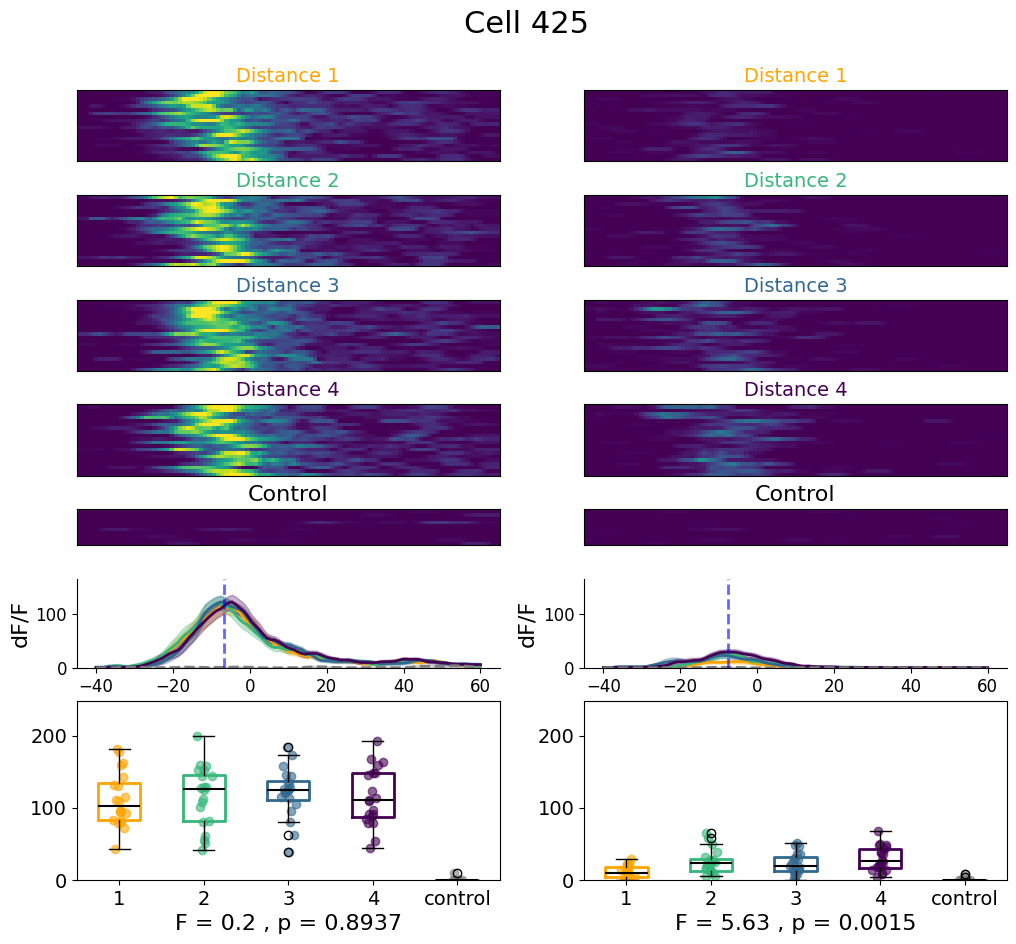

In [103]:
plot_trials_ordered_2(D, cell=425)

In [28]:
# compute cells accepted without median distance method
is_reliable_population = []
reliability_population = []
is_consistent_population = []
distance_population = []

for cell in range(D.dFF.shape[0]):
    
    is_reliable, reliability, _ = D.compute_reliability(cell=cell, n_iterations=200, additional_reliability=False, block='two eye')
    is_consistent, distance = D.is_active(cell, block='two eye')
    is_reliable_population.append(is_reliable)
    reliability_population.append(reliability)
    is_consistent_population.append(is_consistent)
    distance_population.append(distance)

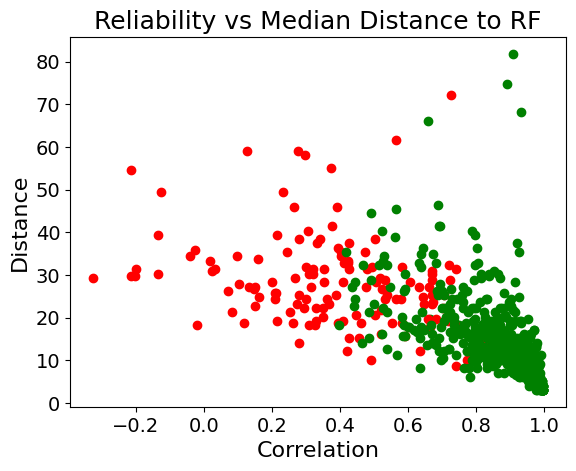

In [40]:
plt.figure()

for i in range(len(is_reliable_population)):
    if is_reliable_population[i]:
        plt.scatter(reliability_population[i], distance_population[i], color='green')
    else:
        plt.scatter(reliability_population[i], distance_population[i], color='red')
        
plt.xlabel('Correlation')
plt.ylabel('Distance')
plt.title('Reliability vs Median Distance to RF')
plt.show()
# plt.scatter(reliability_population, distance_population)

Text(0.5, 0, 'Reliability')

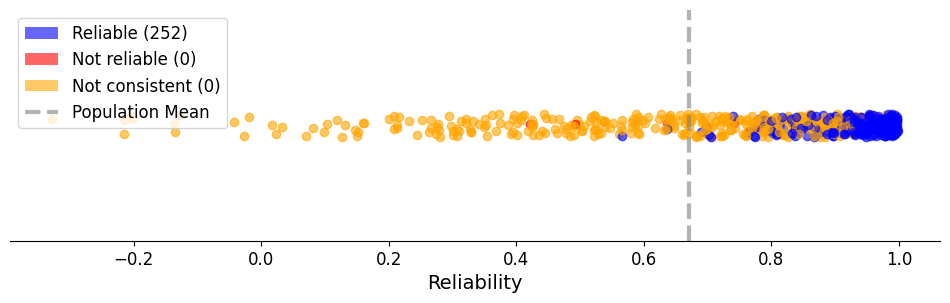

In [45]:
# percentage_reliable = 100 * np.sum(is_reliable) / len(is_reliable)
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
for cell in range(len(is_reliable_population)):
    
    if is_reliable_population[cell] and is_consistent_population[cell]:
        color = 'blue'
    elif is_reliable_population and not is_consistent_population[cell]:
        color = 'orange'
    else:
        color = 'red'
    
    ax.scatter(reliability_population[cell], random.uniform(-.1, .1), color=color, alpha=0.6)

ax.set_ylim(-1, 1)
legend_elements = [Patch(facecolor='blue', alpha=0.6, label='Reliable' + r' (' + str(np.sum(is_reliable_population and is_consistent_population)) + r')'),
                   Patch(facecolor='red', alpha=0.6,
                         label='Not reliable' + r' (' + str(np.sum(np.invert(is_reliable))) + r')'),
                   Patch(facecolor='orange', alpha=0.6, label='Not consistent' + r' (' + str(np.sum(is_reliable_population and not is_consistent_population)) + r')'),
                   Line2D([0], [0], color='gray', lw=3, ls='--', alpha=0.6, label='Population Mean')]
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.axvline(np.mean(reliability), ls='--', alpha=0.6, color='gray', linewidth=3)
ax.set_yticks([])
plt.xticks(fontsize=12)

ax.legend(handles=legend_elements, loc='upper left')

# if title is None:
#     ax.set_title('Reliability: ' + str(round(percentage_reliable, 2)) + '% of cells are reliable', fontsize=16)
# else:
#     ax.set_title(title + ' Reliability: ' + str(round(percentage_reliable, 2)), fontsize=16)

ax.set_xlabel('Reliability', fontsize=14)

In [46]:
# without distance method
is_reliable_one = D.stats['is_reliable_one_eye']
is_reliable_two = D.stats['is_reliable_two_eye']

is_reliable_old_two = []
is_reliable_old_one = []
for cell in range(D.dFF.shape[0]):
    # print cell in new lines
    print('Cell ' + str(cell), end='\r')
    is_reliable_old_two.append(D.compute_reliability(cell=cell, n_iterations=100, additional_reliability=False, block='two eye')[0])
    is_reliable_old_one.append(D.compute_reliability(cell=cell, n_iterations=100, additional_reliability=False, block='one eye')[0])

In [47]:
def extract_modulation(is_reliable_one, is_reliable_two):
    
    type = []
    
    for cell in range(len(is_reliable_one)):
        
        if is_reliable_one[cell] or is_reliable_two[cell]:
            
            is_monocular_modulated = D.compute_distance_modulation(cell=cell, block='one eye')[0]
            is_binocular_modulated = D.compute_distance_modulation(cell=cell, block='two eye')[0]
            
            if is_monocular_modulated and is_binocular_modulated:
                type.append('both')
            elif is_monocular_modulated:
                type.append('monocular')
            elif is_binocular_modulated:
                type.append('binocular')
            else:
                type.append('un-modulated')
            
        else:
            type.append('un-reliable')
            
    return type    

In [48]:
type_classic = extract_modulation(is_reliable_one, is_reliable_two)
type_old = extract_modulation(is_reliable_old_one, is_reliable_old_two)

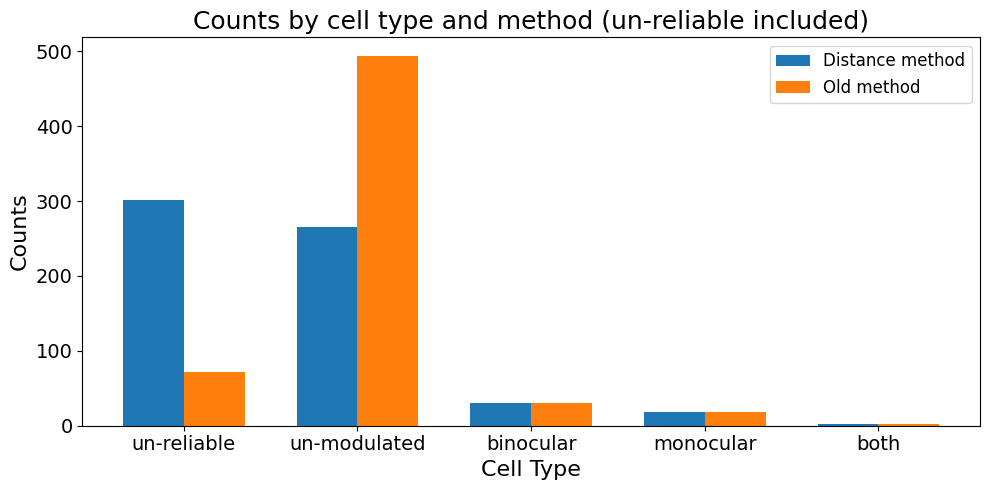

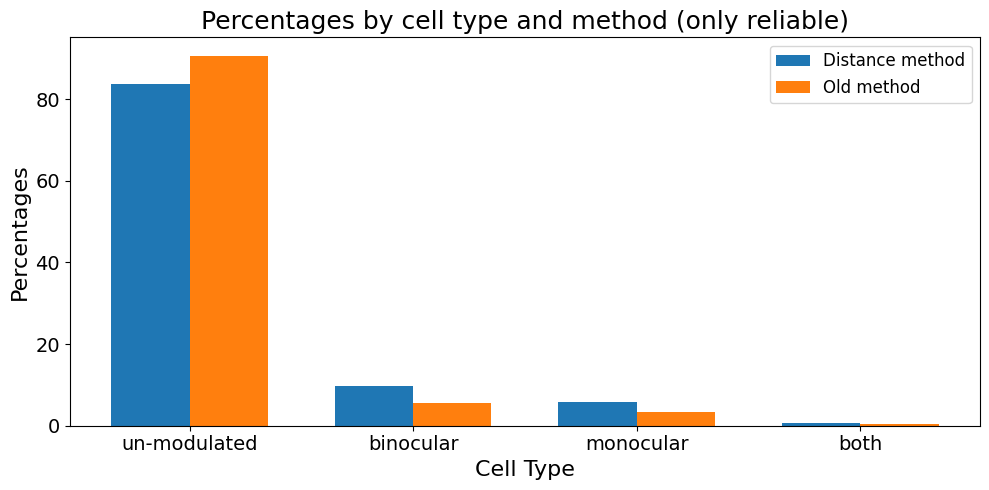

In [50]:
categories = ['un-reliable', 'un-modulated', 'binocular', 'monocular', 'both']
counts_distance = [type_classic.count(cat) for cat in categories]
counts_old= [type_old.count(cat) for cat in categories]

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, counts_distance, width, label='Distance method')
rects2 = ax.bar(x + width/2, counts_old, width, label='Old method')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Counts')
ax.set_title('Counts by cell type and method (un-reliable included)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

fig.tight_layout()

plt.show()

categories = ['un-modulated', 'binocular', 'monocular', 'both']
counts_distance = [type_classic.count(cat) for cat in categories]
counts_old= [type_old.count(cat) for cat in categories]

# Calculate percentages
total_distance = sum(counts_distance)
total_old = sum(counts_old)
percentages_distance = [count / total_distance * 100 for count in counts_distance]
percentages_old = [count / total_old * 100 for count in counts_old]

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, percentages_distance, width, label='Distance method')
rects2 = ax.bar(x + width/2, percentages_old, width, label='Old method')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Percentages')
ax.set_title('Percentages by cell type and method (only reliable)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

fig.tight_layout()
plt.show()